In [1]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from astropy.visualization import simple_norm
from matplotlib import gridspec

In [2]:
def displayFITS(path='/fits'):
    with fits.open(path) as hdul:
        print(hdul.info())
        print(hdul[0].header)
        #print(hdul[1].header)
        image_data = hdul[0].data
    plt.imshow(np.arcsinh(image_data), origin='lower')
    plt.show()
    
def display2FITS(path, ax=None, cmap='viridis', log_a=10000):
    """
    Display a FITS image using a log stretch (via simple_norm) on a provided axis.
    Automatically prints max flux for reference.
    
    Parameters
    ----------
    path : str
        Path to the FITS file.
    ax : matplotlib.axes.Axes, optional
        Axis to plot on. If None, a new figure/axis is created.
    cmap : str
        Colormap to use.
    log_a : float
        Logarithmic stretch parameter (higher = boosts faint pixels more).
    """
    with fits.open(path) as hdul:
        imageFITS = hdul[0].data.astype(float)

    max_flux = np.nanmax(imageFITS)
    print(f"Maximum flux in image: {max_flux:.3e}")

    if ax is None:
        fig, ax = plt.subplots(figsize=(6,6))

    norm = simple_norm(imageFITS, stretch='log', log_a=log_a)
    ax.imshow(imageFITS, origin='lower', cmap=cmap, norm=norm)
    ax.set_title(f"FITS Image (max={max_flux:.3e})")
    return ax

def printFITS(path='/fits'):
    with fits.open(path) as hdul:
        print(hdul.info())
        print(hdul[0].header)
        print(hdul[1].header)
        data = hdul[1].data
        print(data)
    #plt.imshow(np.arcsinh(image_data), origin='lower')
    #plt.show()
    
def fits_to_dataframe(fits_file):
    # Open the FITS file and read data from the first binary table extension
    with fits.open(fits_file) as hdul:
        data = hdul[1].data
        columns = data.columns.names
    
    # Convert to DataFrame with proper endian correction for astropy fits data
    df = pd.DataFrame(np.array(data).byteswap().newbyteorder())
    
    # Optional: clean column names to remove spaces or special characters (if needed)
    # For example, replace spaces with underscores and remove '^' characters
    clean_columns = [col.strip().replace(' ', '_').replace('^', '').replace('/', '_') for col in columns]
    df.columns = clean_columns
    
    # Convert numeric columns to appropriate types (if not done already)
    for col in clean_columns:
        if pd.api.types.is_object_dtype(df[col]):
            try:
                df[col] = pd.to_numeric(df[col], errors='ignore')
            except Exception:
                pass  # leave as is if conversion fails
    
    return df

In [14]:
def compare_sersic_fits(cat_file, statmorph_file):
    # Load data
    with fits.open(cat_file) as hdul_cat:
        data_cat = hdul_cat[1].data
        colnames_cat = data_cat.columns.names
    with fits.open(statmorph_file) as hdul_stat:
        data_stat = hdul_stat[1].data
        colnames_stat = data_stat.columns.names

    # Convert to DataFrames with endian correction
    df_cat = pd.DataFrame(np.array(data_cat).byteswap().newbyteorder())
    df_stat = pd.DataFrame(np.array(data_stat).byteswap().newbyteorder())

    # Use the first column name for ID
    id_col_cat = colnames_cat[0]
    id_col_stat = colnames_stat[0]

    # Cast IDs to int64 for reliable merging
    df_cat[id_col_cat] = df_cat[id_col_cat].astype(np.int64)
    df_stat[id_col_stat] = df_stat[id_col_stat].astype(np.int64)

    # Rename ID columns to a common name for merging
    df_cat = df_cat.rename(columns={id_col_cat: 'gal_id'})
    df_stat = df_stat.rename(columns={id_col_stat: 'gal_id'})

    # Merge on this common 'gal_id'
    merged = pd.merge(df_cat, df_stat, on='gal_id', suffixes=('_cat', '_stat'))

    # Identify columns to compare (exclude 'gal_id')
    cols_cat = [c for c in merged.columns if c.endswith('_cat') and c != 'gal_id_cat']
    cols_stat = [c for c in merged.columns if c.endswith('_stat') and c != 'gal_id_stat']

    # Extract base column names (without suffix)
    base_cols = [c[:-4] for c in cols_cat]  # remove '_cat'
    #base_cols = [c for c in base_cols if not c.startswith('e_')]

    # Build comparison dataframe
    comparison = pd.DataFrame({'gal_id': merged['gal_id']})

    for col in base_cols:
        col_cat = col + '_cat'
        col_stat = col + '_stat'
        if col_cat in merged.columns and col_stat in merged.columns:
            comparison[f'{col}_cat'] = merged[col_cat]
            comparison[f'{col}_stat'] = merged[col_stat]
            # Add difference column if numeric
            if np.issubdtype(merged[col_cat].dtype, np.number) and np.issubdtype(merged[col_stat].dtype, np.number):
                comparison[f'd_{col}'] = merged[col_cat] - merged[col_stat]

    return comparison


Maximum flux in image: 2.041e+00
Maximum flux in image: 2.559e+01


<Axes: title={'center': 'FITS Image (max=2.559e+01)'}>

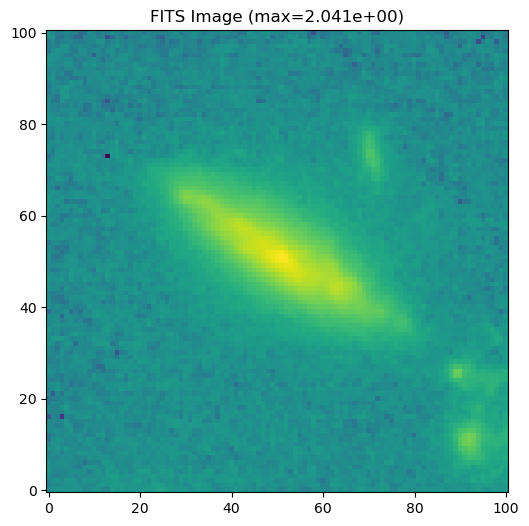

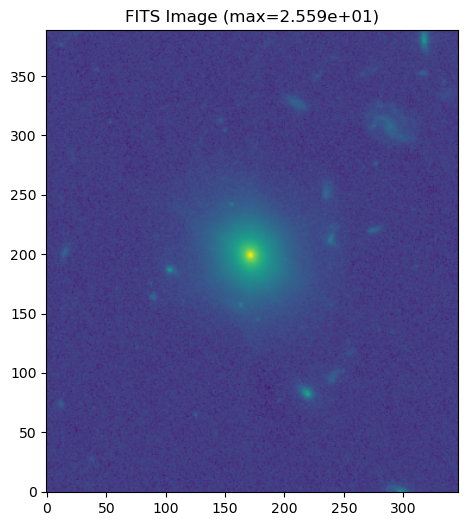

In [15]:
display2FITS('galaxy_cutouts/ceers/f115w/cutout_sci_48.fits')
display2FITS('galaxy_cutouts/jades/f115w/cutout_sci_202206.fits')
#displayFITS('fits/m0912_z0307_f150w_statmorph/psf_f150w.fits')
#print()
#printFITS('fits/m0912_z0307_f150w_statmorph/jades_gds_m0912_z0307_f150w_xdf_gfcat.fits')
#x=fits_to_dataframe('fits/m0912_z0307_f150w_statmorph/results/statmorph_summary.fits')
#display(x)

#printFITS('mastDownload/HLSP/hlsp_jades_jwst_nircam_goods-s-deep_f115w_v2.0/hlsp_jades_jwst_nircam_goods-s-deep_f115w_v2.0_drz.fits')
#display(x)

In [18]:
df_comparison = compare_sersic_fits(
    'fits/m0912_z0307_f150w_statmorph/jades_gds_m0912_z0307_f150w_xdf_gfcat.fits',
    'fits/m0912_z0307_f150w_statmorph/results/statmorph_summary.fits'
)
#df_comparison = compare_sersic_fits(
#    'galaxy_cutouts/hlsp_jades_jwst_nircam_goods-s-deep_segmentation_v2.0_drz.fits',
#    'galaxy_cutouts/results/statmorph_summary.fits'
#)
df_comparison = df_comparison.dropna(axis=1, how='any')

display(df_comparison)

,gal_id,mag_cat,mag_stat,d_mag,R_e_cat,R_e_stat,d_R_e,n_cat,n_stat,d_n,...,P.A._stat,d_P.A.,e_mag_cat,e_Re_cat,e_n_cat,e_q_cat,e_PA_cat,Chi^2/nu_cat,Chi^2/nu_stat,d_Chi^2/nu
0,202206,19.559299,18.829911,0.729388,7.853800,7.562849,0.290951,4.0366,3.940751,0.095849,...,22.274743,0.175957,0.0003,0.0052,0.0028,0.0003,0.0654,1.018583,1.564472,-0.545889
1,202519,23.020300,22.135678,0.884622,10.982000,14.294827,-3.312827,1.0204,0.541707,0.478693,...,-20.431501,-3.840100,0.0021,0.0362,0.0057,0.0010,0.1121,2.131866,0.868014,1.263852
2,202327,23.166500,22.297204,0.869296,8.533200,8.497525,0.035675,1.1002,1.088719,0.011481,...,65.751850,-0.040447,0.0012,0.0172,0.0041,0.0006,0.0526,0.703255,0.716184,-0.012929
3,202891,23.121000,22.178839,0.942161,9.257400,9.995918,-0.738518,1.5124,1.641535,-0.129135,...,-86.579567,0.413963,0.0021,0.0306,0.0057,0.0011,0.1256,0.854240,0.921063,-0.066824
4,204226,18.787100,18.039250,0.747850,16.310499,15.975840,0.334659,3.8202,3.815863,0.004337,...,76.637642,-0.470345,0.0005,0.0202,0.0041,0.0006,0.1941,7.375580,1.234756,6.140824
5,204264,20.157000,19.354114,0.802886,7.768500,7.496381,0.272119,2.6685,2.521529,0.146971,...,82.848955,0.356245,0.0012,0.0203,0.0108,0.0009,0.0833,20.601290,10.411277,10.190013
6,204121,22.920900,21.990056,0.930844,8.800300,10.254508,-1.454208,2.0215,2.452310,-0.430809,...,-1.670493,-0.742607,0.0045,0.0625,0.0151,0.0019,0.1967,2.748317,1.352929,1.395388
7,204131,20.357000,19.472661,0.884339,6.074700,8.047036,-1.972336,1.3120,1.314157,-0.002157,...,2.033615,26.789185,0.0015,0.0139,0.0065,0.0018,0.5247,31.822069,16.129935,15.692134
8,205125,19.603100,18.880791,0.722309,12.639100,12.578058,0.061042,4.3792,4.622635,-0.243435,...,-46.127142,-0.047258,0.0006,0.0179,0.0054,0.0003,0.0314,4.370197,4.250737,0.119460
9,204984,22.438299,21.607085,0.831214,7.820400,7.841872,-0.021472,1.1136,1.122500,-0.008900,...,-53.284357,2.220656,0.0013,0.0171,0.0041,0.0015,0.4614,2.486942,3.298604,-0.811662


In [9]:
def read_statmorph_fits(fits_path, as_rows=False, verbose=True):
    """
    Reads a custom StatMorph summary FITS file (created by write_statmorph_fits)
    and returns all data in a clean dictionary or list of row dicts.

    Parameters
    ----------
    fits_path : str
        Path to the FITS file written by write_statmorph_fits().
    as_rows : bool, optional
        If True, return a list of dictionaries (one per galaxy).
        If False (default), return a column-wise dictionary {col_name: array}.
    verbose : bool, optional
        Print column info and number of entries.

    Returns
    -------
    dict or list of dict
        - If as_rows=False: {col_name: numpy_array}
        - If as_rows=True:  [{col_name: value, ...}, ...]
    """
    with fits.open(fits_path) as hdul:
        data = hdul[1].data  # First extension is the table

        # Get column names and arrays
        col_names = data.names
        out_dict = {col: np.array(data[col]) for col in col_names}

    if verbose:
        print(f"Loaded StatMorph FITS: {fits_path}")
        print(f"Columns: {', '.join(col_names)}")
        print(f"Number of rows: {len(data)}")

    if as_rows:
        # Convert to list of row dicts
        rows = []
        for i in range(len(data)):
            row = {col: data[col][i] for col in col_names}
            rows.append(row)
        return rows

    return out_dict

In [15]:
def plot_chi2_distribution_2(stat_dict, bins=30, log_scale=False, show_mean=True, 
                              save_path=None, outlier_percentile=99, 
                              id_key='Id', crop_extreme_mean=True, show_outliers=True):
    """
    Plot two histograms of Chi^2/nu values (full and zoomed) with robust statistics.
    Includes both standard and trimmed mean/median.
    """

    import numpy as np
    import matplotlib.pyplot as plt

    if 'Chi^2/nu' not in stat_dict:
        raise KeyError("The provided dictionary does not contain 'Chi^2/nu'.")

    chi2 = np.array(stat_dict['Chi^2/nu'], dtype=float)
    chi2 = chi2[np.isfinite(chi2)]

    if len(chi2) == 0:
        print("No valid Chi^2/nu values found.")
        return

    # --- Basic stats ---
    mean_val = np.mean(chi2)
    med_val  = np.median(chi2)
    std_val  = np.std(chi2)

    # --- Outlier detection ---
    cutoff = np.percentile(chi2, outlier_percentile)
    outlier_mask = chi2 > cutoff
    n_outliers = np.sum(outlier_mask)
    outlier_values = chi2[outlier_mask]

    outlier_ids = None
    if id_key in stat_dict:
        ids = np.array(stat_dict[id_key])
        outlier_ids = ids[outlier_mask]

    # --- Symmetric trimming for central percentile ---
    trim_fraction = (100 - outlier_percentile) / 200.0
    low_cut  = np.percentile(chi2, 100 * trim_fraction)
    high_cut = np.percentile(chi2, 100 * (1 - trim_fraction))
    chi2_trimmed = chi2[(chi2 >= low_cut) & (chi2 <= high_cut)]
    trimmed_mean = np.mean(chi2_trimmed)
    trimmed_median = np.median(chi2_trimmed)
    mad = 1.4826 * np.median(np.abs(chi2_trimmed - trimmed_median))

    # --- Crop extreme mean if requested ---
    if crop_extreme_mean:
        zoom_min, zoom_max = chi2_trimmed.min(), chi2_trimmed.max()
        mean_val_plot = mean_val if (zoom_min <= mean_val <= zoom_max) else None
    else:
        mean_val_plot = mean_val

    # --- Determine bins ---
    if log_scale:
        chi2_min_full = max(1e-3, chi2.min())
        chi2_max_full = chi2.max()
        chi2_min_trim = max(1e-3, chi2_trimmed.min())
        chi2_max_trim = chi2_trimmed.max()
        
        bins_full = np.logspace(np.log10(chi2_min_full), np.log10(chi2_max_full), bins)
        bins_trim = np.logspace(np.log10(chi2_min_trim), np.log10(chi2_max_trim), bins)
    else:
        bins_full = bins
        bins_trim = bins

    # --- Plot setup ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

    # Full distribution
    axes[0].hist(chi2, bins=bins_full, color='gray', edgecolor='black', alpha=0.7)
    axes[0].set_title("Full Distribution", fontsize=13)
    axes[0].set_xlabel(r"Reduced $\chi^2$ (Chi$^2$/ν)")
    axes[0].set_ylabel("Number of Galaxies")
    if log_scale:
        axes[0].set_xscale('log')

    # Zoomed distribution
    axes[1].hist(chi2_trimmed, bins=bins_trim, color='gray', edgecolor='black', alpha=0.7)
    axes[1].set_title(f"Zoomed (symmetric {outlier_percentile}%)", fontsize=13)
    axes[1].set_xlabel(r"Reduced $\chi^2$ (Chi$^2$/ν)")
    if log_scale:
        axes[1].set_xscale('log')

    # --- Mark outliers on zoomed plot ---
    if show_outliers and n_outliers > 0:
        axes[1].scatter(np.full(n_outliers, chi2_trimmed.max()*1.02), 
                        np.arange(n_outliers), 
                        color='red', label=f"{n_outliers} outliers", marker='x', s=40)

    # --- Mark means and medians ---
    if show_mean:
        # Full distribution
        axes[0].axvline(mean_val, color='red', linestyle='--', lw=1.2, label=f"Mean (all) = {mean_val:.2f}")
        axes[0].axvline(med_val, color='purple', linestyle='-.', lw=1.2, label=f"Median (all) = {med_val:.2f}")
        axes[0].axvline(trimmed_mean, color='green', linestyle='--', lw=1.2, label=f"Trimmed Mean = {trimmed_mean:.2f}")
        #axes[0].axvline(trimmed_median, color='blue', linestyle=':', lw=1.2, label=f"Trimmed Median = {trimmed_median:.2f}")
        axes[0].legend(fontsize=8)

        # Zoomed distribution
        if mean_val_plot is not None:
            axes[1].axvline(mean_val_plot, color='red', linestyle='--', lw=1.2, label=f"Mean (all) = {mean_val:.2f}")
        axes[1].axvline(med_val, color='purple', linestyle='-.', lw=1.2, label=f"Median (all) = {med_val:.2f}")
        axes[1].axvline(trimmed_mean, color='green', linestyle='--', lw=1.2, label=f"Trimmed Mean = {trimmed_mean:.2f}")
        #axes[1].axvline(trimmed_median, color='blue', linestyle=':', lw=1.2, label=f"Trimmed Median = {trimmed_median:.2f}")
        axes[1].legend(fontsize=8)

    plt.tight_layout()

    # --- Save or show ---
    if save_path:
        plt.savefig(save_path, dpi=200)
        plt.close(fig)
        print(f"Saved Chi^2 distribution plot to: {save_path}")
    else:
        plt.show()

    # --- Summary output ---
    summary = {
        'count': len(chi2),
        'mean': mean_val,
        'median': med_val,
        'trimmed_mean': trimmed_mean,
        'trimmed_median': trimmed_median,
        'mad': mad,
        'cutoff': cutoff,
        'n_outliers': int(n_outliers),
        'outlier_values': outlier_values,
        'outlier_ids': outlier_ids,
        'chi2_trimmed': chi2_trimmed,
        'low_cut': low_cut,
        'high_cut': high_cut
    }

    # --- Print summary ---
    print("\nReduced Chi² Statistics:")
    print(f"  Count = {len(chi2)}")
    print(f"  Mean (all)        = {mean_val:.3f}")
    print(f"  Median (all)      = {med_val:.3f}")
    print(f"  Trimmed Mean      = {trimmed_mean:.3f}")
    print(f"  Trimmed Median    = {trimmed_median:.3f}")
    print(f"  MAD (robust σ)    = {mad:.3f}")
    print(f"  Outliers (> {outlier_percentile}th percentile): {n_outliers}")
    if outlier_ids is not None and n_outliers > 0 and n_outliers <= 15:
        print("  Outlier IDs:", outlier_ids)
    elif n_outliers > 15:
        print("  (Too many outliers to list.)")

    return summary


In [16]:
def plot_sersic_n_distribution(stat_dict, bins=30, log_scale=False, show_mean=True, 
                               save_path=None, outlier_percentile=99, 
                               id_key='Id', crop_extreme_mean=True, show_outliers=True):
    """
    Plot two histograms of Sérsic index (n) values with robust statistics.
    Includes both standard and trimmed medians for comparison.
    
    Parameters
    ----------
    stat_dict : dict
        Dictionary containing 'n' and optionally galaxy IDs.
    bins : int
        Number of bins for the histogram (linear) or number of log bins if log_scale=True.
    log_scale : bool
        Whether to use logarithmic x-axis.
    show_mean : bool
        Whether to plot mean and median lines.
    save_path : str
        If provided, saves the figure to this path.
    outlier_percentile : float
        Percentile to define the upper limit for the zoomed histogram and trimming.
    id_key : str
        Key in stat_dict containing galaxy IDs.
    crop_extreme_mean : bool
        If True, mean is not plotted on zoomed plot if it lies outside the zoomed data.
    show_outliers : bool
        If True, marks outliers separately on zoomed plot.
    """

    import numpy as np
    import matplotlib.pyplot as plt

    if 'n' not in stat_dict:
        raise KeyError("The provided dictionary does not contain 'n' (Sérsic index).")

    n_vals = np.array(stat_dict['n'], dtype=float)
    n_vals = n_vals[np.isfinite(n_vals)]

    if len(n_vals) == 0:
        print("No valid Sérsic index (n) values found.")
        return

    # --- Basic stats ---
    mean_val = np.mean(n_vals)
    med_val  = np.median(n_vals)
    std_val  = np.std(n_vals)

    # --- Outlier detection ---
    cutoff = np.percentile(n_vals, outlier_percentile)
    outlier_mask = n_vals > cutoff
    n_outliers = np.sum(outlier_mask)
    outlier_values = n_vals[outlier_mask]

    outlier_ids = None
    if id_key in stat_dict:
        ids = np.array(stat_dict[id_key])
        outlier_ids = ids[outlier_mask]

    # --- Symmetric trimming for central percentile ---
    trim_fraction = (100 - outlier_percentile) / 200.0
    low_cut  = np.percentile(n_vals, 100 * trim_fraction)
    high_cut = np.percentile(n_vals, 100 * (1 - trim_fraction))
    n_trimmed = n_vals[(n_vals >= low_cut) & (n_vals <= high_cut)]
    trimmed_mean = np.mean(n_trimmed)
    trimmed_median = np.median(n_trimmed)
    mad = 1.4826 * np.median(np.abs(n_trimmed - trimmed_median))

    # --- Crop extreme mean if requested ---
    if crop_extreme_mean:
        zoom_min, zoom_max = n_trimmed.min(), n_trimmed.max()
        mean_val_plot = mean_val if zoom_min <= mean_val <= zoom_max else None
    else:
        mean_val_plot = mean_val

    # --- Determine bins ---
    if log_scale:
        n_min_full = max(1e-2, n_vals.min())
        n_max_full = n_vals.max()
        n_min_trim = max(1e-2, n_trimmed.min())
        n_max_trim = n_trimmed.max()
        
        bins_full = np.logspace(np.log10(n_min_full), np.log10(n_max_full), bins)
        bins_trim = np.logspace(np.log10(n_min_trim), np.log10(n_max_trim), bins)
    else:
        bins_full = bins
        bins_trim = bins

    # --- Plot setup ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

    # Full distribution
    axes[0].hist(n_vals, bins=bins_full, color='gray', edgecolor='black', alpha=0.7)
    axes[0].set_title("Full Distribution", fontsize=13)
    axes[0].set_xlabel("Sérsic Index (n)")
    axes[0].set_ylabel("Number of Galaxies")
    if log_scale:
        axes[0].set_xscale('log')

    # Zoomed distribution
    axes[1].hist(n_trimmed, bins=bins_trim, color='gray', edgecolor='black', alpha=0.7)
    axes[1].set_title(f"Zoomed (symmetric {outlier_percentile}%)", fontsize=13)
    axes[1].set_xlabel("Sérsic Index (n)")
    if log_scale:
        axes[1].set_xscale('log')

    # --- Mark outliers on zoomed plot ---
    if show_outliers and n_outliers > 0:
        axes[1].scatter(np.full(n_outliers, n_trimmed.max()*1.02), 
                        np.arange(n_outliers), 
                        color='red', label=f"{n_outliers} outliers", marker='x', s=40)

    # --- Mark means and medians ---
    if show_mean:
        # Full
        axes[0].axvline(mean_val, color='red', linestyle='--', lw=1.2, label=f"Mean = {mean_val:.2f}")
        axes[0].axvline(med_val, color='orange', linestyle='-', lw=1.2, label=f"Median = {med_val:.2f}")
        axes[0].axvline(trimmed_mean, color='green', linestyle='--', lw=1.2, label=f"Trimmed Mean = {trimmed_mean:.2f}")
        #axes[0].axvline(trimmed_median, color='blue', linestyle=':', lw=1.2, label=f"Trimmed Median = {trimmed_median:.2f}")
        axes[0].legend(fontsize=8)

        # Zoomed
        if mean_val_plot is not None:
            axes[1].axvline(mean_val_plot, color='red', linestyle='--', lw=1.2, label=f"Mean = {mean_val:.2f}")
        axes[1].axvline(med_val, color='orange', linestyle='-', lw=1.2, label=f"Median = {med_val:.2f}")
        axes[1].axvline(trimmed_mean, color='green', linestyle='--', lw=1.2, label=f"Trimmed Mean = {trimmed_mean:.2f}")
        #axes[1].axvline(trimmed_median, color='blue', linestyle=':', lw=1.2, label=f"Trimmed Median = {trimmed_median:.2f}")
        axes[1].legend(fontsize=8)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=200)
        plt.close(fig)
        print(f"Saved Sérsic n distribution plot to: {save_path}")
    else:
        plt.show()

    # --- Summary output ---
    summary = {
        'count': len(n_vals),
        'mean': mean_val,
        'median': med_val,
        'trimmed_mean': trimmed_mean,
        'trimmed_median': trimmed_median,
        'mad': mad,
        'cutoff': cutoff,
        'n_outliers': int(n_outliers),
        'outlier_values': outlier_values,
        'outlier_ids': outlier_ids,
        'n_trimmed': n_trimmed,
        'low_cut': low_cut,
        'high_cut': high_cut
    }

    # --- Print summary ---
    print("\nSérsic Index (n) Statistics:")
    print(f"  Count = {len(n_vals)}")
    print(f"  Mean (all)        = {mean_val:.3f}")
    print(f"  Median (all)      = {med_val:.3f}")
    print(f"  Trimmed Mean      = {trimmed_mean:.3f}")
    print(f"  Trimmed Median    = {trimmed_median:.3f}")
    print(f"  MAD (robust σ)    = {mad:.3f}")
    print(f"  Outliers (> {outlier_percentile}th percentile): {n_outliers}")
    if outlier_ids is not None and n_outliers > 0 and n_outliers <= 15:
        print("  Outlier IDs:", outlier_ids)
    elif n_outliers > 15:
        print("  (Too many outliers to list.)")

    return summary


In [17]:
jades_f115w = read_statmorph_fits("galaxy_cutouts/jades/f115w/results/statmorph_summary.fits")
ceers_f115w = read_statmorph_fits("galaxy_cutouts/ceers/f115w/results/statmorph_summary.fits")

Loaded StatMorph FITS: galaxy_cutouts/jades/f115w/results/statmorph_summary.fits
Columns: Id, Survey, mag, R_e, n, q, P.A., e_mag, e_Re, e_n, e_q, e_PA, Chi^2/nu
Number of rows: 899
Loaded StatMorph FITS: galaxy_cutouts/ceers/f115w/results/statmorph_summary.fits
Columns: Id, Survey, mag, R_e, n, q, P.A., e_mag, e_Re, e_n, e_q, e_PA, Chi^2/nu
Number of rows: 105


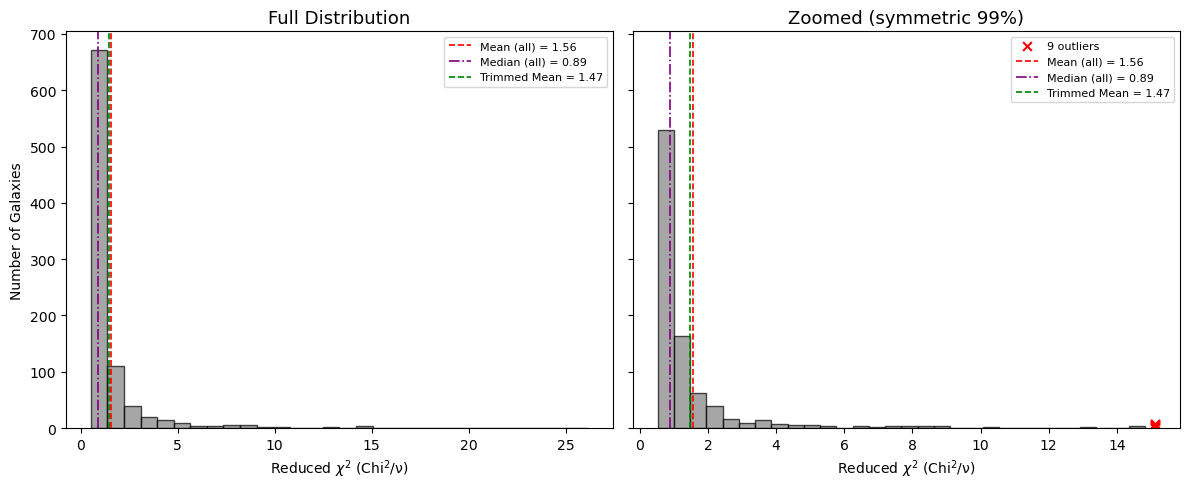


Reduced Chi² Statistics:
  Count = 899
  Mean (all)        = 1.559
  Median (all)      = 0.887
  Trimmed Mean      = 1.467
  Trimmed Median    = 0.887
  MAD (robust σ)    = 0.334
  Outliers (> 99th percentile): 9
  Outlier IDs: [202792. 204395. 204594. 205445. 206609. 207204. 209032. 210406. 210989.]


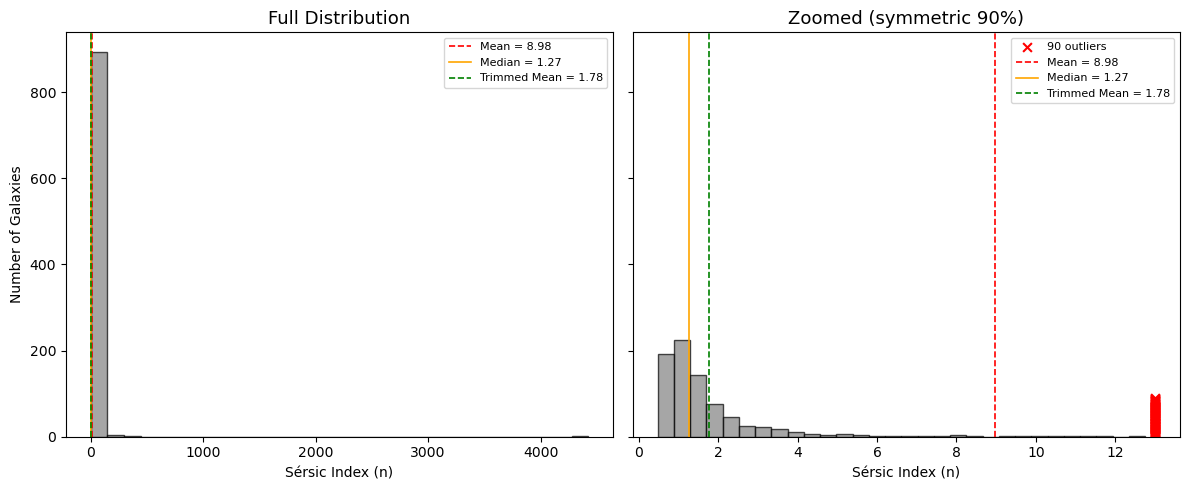


Sérsic Index (n) Statistics:
  Count = 899
  Mean (all)        = 8.976
  Median (all)      = 1.269
  Trimmed Mean      = 1.783
  Trimmed Median    = 1.269
  MAD (robust σ)    = 0.647
  Outliers (> 90th percentile): 90
  (Too many outliers to list.)


In [18]:
x=plot_chi2_distribution_2(jades_f115w, log_scale=False)
x2=plot_sersic_n_distribution(jades_f115w,outlier_percentile=90, log_scale=False)

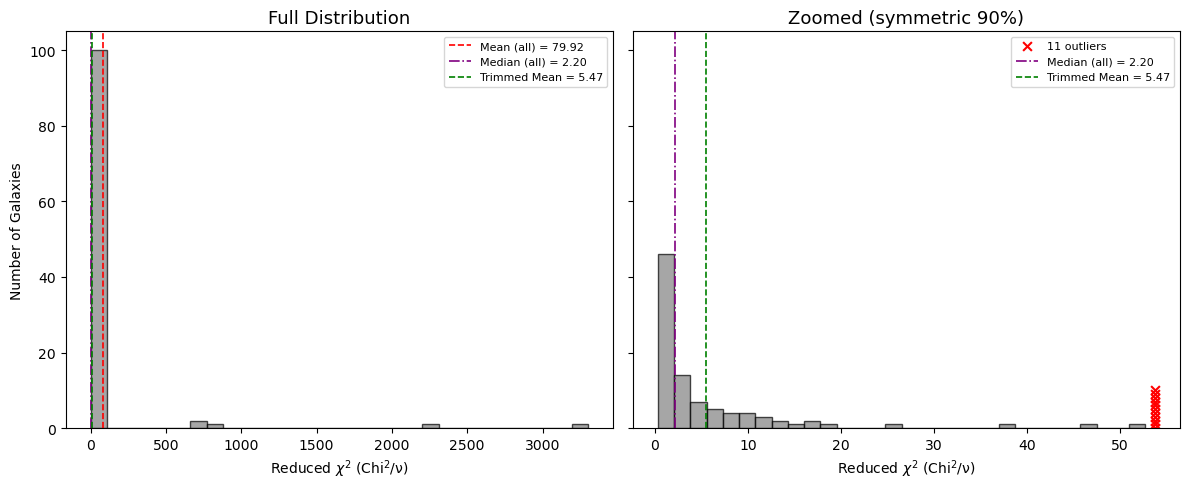


Reduced Chi² Statistics:
  Count = 105
  Mean (all)        = 79.922
  Median (all)      = 2.203
  Trimmed Mean      = 5.472
  Trimmed Median    = 2.203
  MAD (robust σ)    = 2.572
  Outliers (> 90th percentile): 11
  Outlier IDs: [105.  12.  16.  17.  24.  25.  26.  55.  86.  89.   9.]


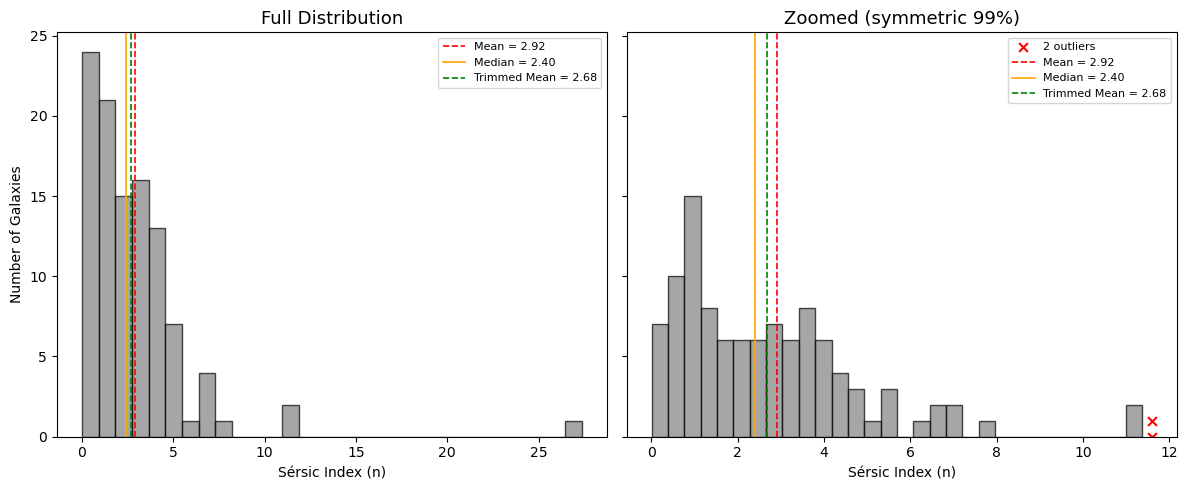


Sérsic Index (n) Statistics:
  Count = 105
  Mean (all)        = 2.918
  Median (all)      = 2.396
  Trimmed Mean      = 2.683
  Trimmed Median    = 2.301
  MAD (robust σ)    = 2.058
  Outliers (> 99th percentile): 2
  Outlier IDs: [16. 81.]


In [19]:
y=plot_chi2_distribution_2(ceers_f115w,outlier_percentile=90, log_scale=False)
y2=plot_sersic_n_distribution(ceers_f115w, log_scale=False)